In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,GlobalAveragePooling2D,Input
from tensorflow.keras.utils import to_categorical

In [3]:
dataset_path = r"C:\Users\user5\OneDrive\Desktop\Deep-Learning\Dataset\101_ObjectCategories"

In [6]:
categories = ["airplanes", "Motorbikes", "sunflower", "elephant", "butterfly"]

In [7]:
for c in categories:
    folder = os.path.join(dataset_path,c)
    print(c,":",len(os.listdir(folder)),"images")

airplanes : 800 images
Motorbikes : 798 images
sunflower : 85 images
elephant : 64 images
butterfly : 91 images


In [8]:
images = []
labels = []

for index,category in enumerate(categories):
    folder = os.path.join(dataset_path,category)
    for file in os.listdir(folder):
        img_path = os.path.join(folder,file)
        img = load_img(img_path, target_size=(224,224))
        img = img_to_array(img)
        images.append(img)
        labels.append(index)

X = np.array(images)
Y = np.array(labels)

print("X_shape: ", X.shape)
print("Y_shape: ", Y.shape)

X_shape:  (1838, 224, 224, 3)
Y_shape:  (1838,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,Y,test_size=0.2,random_state=42,stratify=Y
)

print("Training images: ",X_train.shape)
print("Test images: ",y_train.shape)

Training images:  (1470, 224, 224, 3)
Test images:  (1470,)


In [12]:
vgg_base = VGG16(weights = "imagenet", include_top=False, input_shape=(224,224,3))

for layer in vgg_base.layers:
    layer.trainable = False

vgg_base.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 18s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 7, 7, 512)           │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [13]:
feature_extraction = Sequential([
    vgg_base,
    GlobalAveragePooling2D()
])

train_features = feature_extraction.predict(X_train, batch_size=32)
test_features = feature_extraction.predict(X_test, batch_size=32)

46/46 ━━━━━━━━━━━━━━━━━━━━ 121s 3s/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 30s 3s/step


In [15]:
print("Train features shape:", train_features.shape)
print("Test features shape:", test_features.shape)

Train features shape: (1470, 512)
Test features shape: (368, 512)


In [19]:
classifier = Sequential([
    Input(shape=(512,)),
    Dense(128,activation="relu"),
    Dense(5,activation="softmax")
])

In [20]:
classifier.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                      │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 66,309 (259.02 KB)

 Trainable params: 66,309 (259.02 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
classifier.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics = ["accuracy"])

In [22]:
history = classifier.fit(
    train_features, y_train, epochs=10, batch_size=64, validation_split=0.1
)

Epoch 1/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9078 - loss: 0.5946 - val_accuracy: 1.0000 - val_loss: 0.0029
Epoch 2/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9947 - loss: 0.0221 - val_accuracy: 0.9932 - val_loss: 0.0116
Epoch 3/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9970 - loss: 0.0105 - val_accuracy: 1.0000 - val_loss: 4.1368e-04
Epoch 4/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 1.0000 - val_loss: 9.7922e-04
Epoch 5/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 2.2320e-04 - val_accuracy: 1.0000 - val_loss: 0.0018
Epoch 6/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 1.5725e-04 - val_accuracy: 1.0000 - val_loss: 0.0018
Epoch 7/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 1.3324e-04 - val_accuracy: 1.0000 - val_loss: 0.0015
Epoch 8/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 1.1762e-04 - val_acc

In [25]:
test_loss,test_accuracy = classifier.evaluate(test_features,y_test)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 8.0835e-04


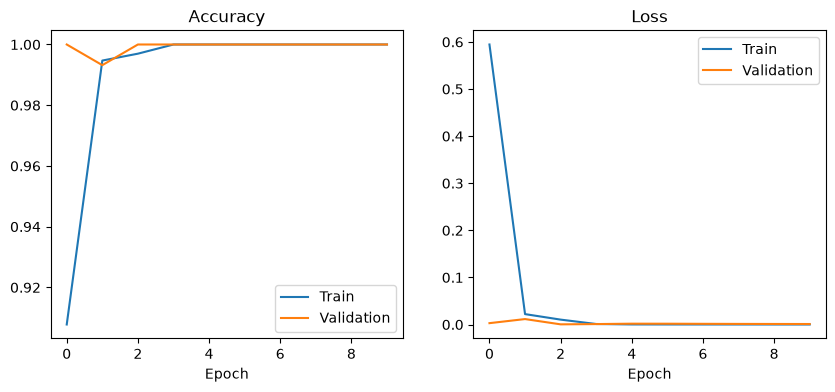

In [26]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.show()

In [27]:
predictions = classifier.predict(test_features[:5])
for i in range(5):
    print("Actual:", categories[y_test[i]], "| Predicted:", categories[np.argmax(predictions[i])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
Actual: Motorbikes | Predicted: Motorbikes
Actual: Motorbikes | Predicted: Motorbikes
Actual: airplanes | Predicted: airplanes
Actual: Motorbikes | Predicted: Motorbikes
Actual: airplanes | Predicted: airplanes
